# QBO wind, temperature and thermal-wind coupling

## Purpose

Evaluate the QBO zonal-wind evolution of the experiments against ERA-Interim and ERA5, the QBO temperature signal, and the thermal-wind consistency of temperature and wind shear.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly CMIP-named `ua` and `ta` (`cmip_ts/monthly`, 19 pressure levels). References: ERA5 and ERA-Interim monthly pressure-level `ua` and `ta` (E3SM Diags time series under `OBSERVATION_ROOT`; 0.25 and 0.75 degree, read lazily and subset to the model levels and 5S-5N before computing).

## Method

5S-5N cos-lat weighted zonal mean on the model levels (hPa), for `ua` and `ta`. Amplitudes: half peak-to-peak, RMS, and detrended RMS over the record (for `ta` after removing the month-of-year climatology; the saved section stays raw). Spectral amplitudes need >= 8 years and are not computed for 2012-2013.

Wind. Scores: RMSE/PCC of the sections, averaged over both reanalyses and against `REFERENCE` alone, with a 95% moving-block bootstrap CI (overlapping `BLOCK_LEN`-month blocks; with 24 months this CI is rough). RMSE/PCC over the record mix the initialized memory with the model's own QBO, so memory and timing are scored separately against the mean of both reanalyses:

* `memory_months`: lead months before the profile correlation (10-100 hPa) with the reference stays below `MEMORY_THRESHOLD` for two months;
* westerly/easterly onset month at each level, following the descending shear zone from 10 hPa, and its error;
* descent rate of the westerly zone over 10-50 hPa (km/month, scale height 7 km) and its error.

Temperature. Thermal-wind balance gives a strong negative correlation between T′ and ∂U/∂ln p. The coupling and the amplitudes over the record are properties of the model physics, not of the initial state: they are scored as a pseudo-ensemble check (the reanalyses against the range of the 8 runs). The initial state shows in the errors instead: with α the T′-on-∂U/∂ln p slope of the reanalyses, α ΔS is the part of a temperature error ΔT supported by the shear error ΔS, and ΔT − α ΔS the unbalanced part, tracked by lead month and grouped by atmospheric initial state.

Attribution (`util/hind_factorial.py`): each score is fitted as μ + atm + lnd over the 8 single runs; the interaction residual is the noise floor setting each effect's 95% interval. Onsets that do not occur within the record are NaN (CTRL and DARTBA at 30-50 hPa), so effects against the piC atmosphere are then not estimable.

## Outputs

`data/hind_atm_eval/qbo/qbo_<SOURCE>_<ua|ta>_<period>.nc` (the `ua` sections are also read by notebook 02), `qbo_ua_skill_<REFS>.csv`, `qbo_ua_timing.csv`, `qbo_ua_effects.csv`, `qbo_ta_physics.csv` (per source), `qbo_ta_physics_range.csv` (reanalyses vs model range), `qbo_ta_physics_effects.csv`, `qbo_thermal_wind_consistency.csv`; figures in `figure/hind_atm_eval/qbo/`:

1. U time-pressure sections of the reference and all sources, RMSE/PCC vs the reference annotated, and source − reference differences.
2. U RMS amplitude profiles.
3. RMSE/PCC skill bars, averaged over both reanalyses (their own disagreement drawn as a floor) and vs one reference.
4. Persistence of the initial vertical profile and correlation with the reference vs lead month.
5. Westerly onset by level and U at 30/50 hPa vs lead month.
6. Factorial scorecard of RMSE, PCC, memory and timing.
7. T anomaly sections (`FIELD`/`ANOM_MODE`; default: anomalies from the reference monthly climatology, comparable across sources) and their differences from the reference.
8. T amplitude profiles (seasonal cycle removed) and vertical coherence with `COHERENCE_LEVEL`.
9. corr_t[T′, ∂U/∂ln p] by level, mean over `SHEAR_BAND`, and T′ vs ∂U/∂ln p in `SCATTER_LAYER`.
10. Factorial scorecard of the coupling and amplitude.
11. Paper figure, thermal-wind consistency of the temperature errors by atmospheric initial state (`qbo_thermal_wind_consistency.png`): ΔT and α ΔS for DART40 and CAPT10, RMS of ΔT − α ΔS vs lead month, months 1-3 profiles. The ERA5 (CAPT) atmosphere cools the 30-70 hPa layer by 8-10 K in the first months with no matching shear error; the DART atmosphere stays near balance. Run with `EXPERIMENTS_FULL` for the range over land initial states.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

# Experiments: run key (file names, tables) -> figure label. Labels follow fcst_atm_eval: the experiment
# whose initial state the run starts from (CTRL10: piControl, CAPT10: ERA5, DART40: DART), written
# "<atm>A-<lnd>L" when atmosphere and land come from different ones. EXPERIMENTS_FULL (backup) is the full
# atm x lnd factorial, needed for the initial-state attribution (factorial effects and noise floors).
EXPERIMENTS_FULL = {
    "CTRL": "CTRL10-S0",           # piControl atm + piControl lnd
    "DARTOP": "DART40-S0",         # DART atm + DART lnd
    "ERA5OP": "CAPT10-S0",         # ERA5 atm + ERA5-forced lnd
    "ERA5DL": "CAPTA-DARTL-S0",    # ERA5 atm + DART lnd
    "ERA5BL": "CAPTA-CTRLL-S0",    # ERA5 atm + piControl lnd
    "DARTBL": "DARTA-CTRLL-S0",    # DART atm + piControl lnd
    "DARTBA": "CTRLA-DARTL-S0",    # piControl atm + DART lnd
    "DARTAE": "DARTA-CAPTL-S0",    # DART atm + ERA5-forced lnd
}

EXPERIMENTS_FCST = {k: EXPERIMENTS_FULL[k] for k in ("CTRL", "ERA5OP", "DARTOP")}
EXPERIMENTS = EXPERIMENTS_FCST  # or EXPERIMENTS_FULL
REFERENCES = ("ERAI", "ERA5")  # sections for both; skill averaged over them
REFERENCE = "ERAI"             # sections, differences and single-reference skill against this one
OTHER_REANALYSIS = "ERA5"      # also drawn as a source
LAT_BAND = (-5.0, 5.0)
# Wind (ua) scores
BLOCK_LEN = 6                  # months per bootstrap block
N_BOOT = 500
MEMORY_THRESHOLD = 0.5       # profile correlation below which the initial QBO phase is lost
TIMING_LEVELS = (10.0, 20.0, 30.0, 50.0, 70.0)  # hPa
# Temperature (ta) and thermal-wind coupling
FIELD = "qbo_anom"          # "qbo" (raw) | "qbo_anom"
ANOM_MODE = "ref_clim"      # "own_clim" | "ref_clim" | "first_month"
COHERENCE_LEVEL = 30.0      # hPa
SHEAR_BAND = (10.0, 70.0)   # hPa
SCATTER_LAYER = (20.0, 50.0)
SCATTER_SOURCES = ("ERA5", "DARTOP", "ERA5OP", "CTRL", "DARTBA")  # those not in REFERENCES/EXPERIMENTS are skipped
FORCE_COMPUTE = False
FONT_SCALE = 14
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask
from util.hind_factorial import relabel_figure

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'qbo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
FACTORIAL = set(EXPERIMENTS) == set(EXPERIMENTS_FULL)  # the atm x lnd attribution needs all 8 runs
SET_NAME = "full" if FACTORIAL else "fcst_aligned" if set(EXPERIMENTS) == set(EXPERIMENTS_FCST) else "subset"
table_dir = data_dir
if not FACTORIAL:  # tables and figures of a subset kept apart from the full set; per-source files are shared
    table_dir, figure_dir = data_dir / SET_NAME, figure_dir / SET_NAME
    for d in (table_dir, figure_dir):
        d.mkdir(exist_ok=True)
print(f"[DATA] {data_dir}\n[TABLE] {table_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    relabel_figure(fig, EXPERIMENTS_FULL)  # run keys -> figure labels
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the (source, variable) pairs whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from configs.hind_experiment_config import PERIOD
from util.qbo_diagnostics import open_qbo_input, qbo_section_path

VARIABLES = ("ua", "ta")
SOURCES = (*REFERENCES, *EXPERIMENTS)
scatter_sources = tuple(s for s in SCATTER_SOURCES if s in SOURCES)
paths = {(s, v): qbo_section_path(data_dir, s, v) for v in VARIABLES for s in SOURCES}
inputs = {(s, v): open_qbo_input(s, v, data_root=INPUT_DATA_ROOT, **ROOTS)
          for (s, v), p in paths.items() if FORCE_COMPUTE or not p.exists()}
print(f"[READ] {', '.join(f'{s}/{v}' for s, v in inputs) or 'nothing: every section is saved'}")

[READ] nothing: every section is saved


## 5. Derive

Equatorial time-height section and amplitude profiles per source and variable (for `ta` with the seasonal cycle removed). The expensive reductions of every source and both variables are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.qbo_diagnostics import QboAnalyzer, QboConfig

analyzers = {v: QboAnalyzer(QboConfig.for_variable(v, lat_band=LAT_BAND)) for v in VARIABLES}
reduced = compute_all({(s, v): analyzers[v].reduce(da) for (s, v), da in inputs.items()})
derived = {(s, v): analyzers[v].compute_metrics(f"{s}_{v}_{PERIOD}", da).assign_attrs(source=s)
           for (s, v), da in reduced.items()}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: RMS amplitude at 30 hPa per source and variable.

In [6]:
for key, ds in derived.items():
    ds.to_netcdf(paths[key])
    print(f"[WRITE] {paths[key]}")
sections = {v: {s: xr.load_dataset(paths[s, v]) for s in SOURCES} for v in VARIABLES}
display(pd.DataFrame({v: {s: float(ds.amp_rms.sel(plev=30)) for s, ds in sections[v].items()}
                      for v in VARIABLES}).add_prefix("amp_rms_30hPa_").round(2))

,amp_rms_30hPa_ua,amp_rms_30hPa_ta
ERAI,18.97,1.96
ERA5,19.06,1.99
CTRL,12.83,1.73
ERA5OP,17.71,2.40
DARTOP,18.41,1.63


## 7. Scores

### 7.1 Wind

RMSE/PCC of every experiment, averaged over `REFERENCES` and against `REFERENCE`; memory and phase timing against the mean of `REFERENCES`; factorial effects of the initial states on each score.

In [7]:
from util.hind_factorial import factorial_effects
from util.qbo_plotting import QboPlotParameter, QboPlotter, qbo_timing_table

plotter = QboPlotter(QboPlotParameter.for_variable("ua"), data_dir)
skill = {}
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    skill[tag] = plotter.skill_table(refs, EXPERIMENTS, n_boot=N_BOOT, block_len=BLOCK_LEN)
    skill[tag].to_csv(table_dir / f"qbo_ua_skill_{tag}.csv", index=False)
    print(f"[WRITE] {table_dir / f'qbo_ua_skill_{tag}.csv'}")
    display(skill[tag].round(2))

timing = qbo_timing_table(data_dir, REFERENCES, EXPERIMENTS, levels_hpa=TIMING_LEVELS,
                          memory_threshold=MEMORY_THRESHOLD)
timing.to_csv(table_dir / "qbo_ua_timing.csv")
print(f"[WRITE] {table_dir / 'qbo_ua_timing.csv'}")
display(timing[["memory_months", "W_onset_10", "W_onset_30", "W_onset_50", "W_onset_70",
                "descent_km_per_month"]].round(1))

SCORE_COLUMNS = {"rmse": ("RMSE (m/s)", False), "pcc": ("PCC", True), "memory_months": ("Memory (months)", True),
                 "abs_W_onset_err_30": ("|W onset error| 30 hPa (months)", False),
                 "abs_W_onset_err_50": ("|W onset error| 50 hPa (months)", False),
                 "descent_err": ("Descent-rate error (km/month)", False)}
scores = pd.concat([skill["_".join(REFERENCES)].set_index("source")[["rmse", "pcc"]],
                    timing.loc[list(EXPERIMENTS)]], axis=1)[list(SCORE_COLUMNS)].astype(float)
if FACTORIAL:
    effects = factorial_effects(scores)
    effects.to_csv(table_dir / "qbo_ua_effects.csv", index=False)
    print(f"[WRITE] {table_dir / 'qbo_ua_effects.csv'}")
    display(effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))
else:
    print(f"[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skill_ERAI_ERA5.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.19,-0.33,15.78,17.56,-0.60,-0.20,0.14,0.02
1,ERA5OP,14.48,0.15,13.38,15.91,-0.08,0.30,0.05,0.02
2,DARTOP,12.71,0.30,11.50,14.23,0.05,0.45,0.07,0.01


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skill_ERAI.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.33,-0.31,15.90,17.64,-0.58,-0.16,0.0,0.0
1,ERA5OP,14.52,0.17,13.43,15.89,-0.07,0.31,0.0,0.0
2,DARTOP,12.78,0.31,11.53,14.23,0.06,0.45,0.0,0.0


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_timing.csv


,memory_months,W_onset_10,W_onset_30,W_onset_50,W_onset_70,descent_km_per_month
source,,,,,,
ERAI,24.0,4.0,13.5,16.7,19.1,0.9
ERA5,24.0,4.0,13.4,16.7,19.0,0.9
CTRL,0.0,17.7,NaN,NaN,NaN,NaN
ERA5OP,2.0,2.0,4.9,7.6,15.3,2.0
DARTOP,5.0,2.3,6.2,8.8,15.3,1.7


[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)


### 7.2 Temperature and thermal-wind coupling

Per source: corr_t[T′, ∂U/∂ln p] averaged over `SHEAR_BAND` and the T and U RMS amplitudes at `COHERENCE_LEVEL`; the reanalyses against the range of the 8 runs, and the factorial effects of the initial states.

In [8]:
from util.hind_factorial import factorial_effects, model_range_check
from util.qbo_plotting import t_shear_corr_profile

ref_t = sections["ta"][REFERENCE].qbo
physics = pd.DataFrame({s: {
    "corr_T_shear": float(t_shear_corr_profile(data_dir, s, ref_t=ref_t).sel(plev=slice(*SHEAR_BAND)).mean()),
    f"T_amp_{COHERENCE_LEVEL:g}hPa": float(sections["ta"][s].amp_rms.sel(plev=COHERENCE_LEVEL)),
    f"U_amp_{COHERENCE_LEVEL:g}hPa": float(sections["ua"][s].amp_rms.sel(plev=COHERENCE_LEVEL)),
} for s in SOURCES}).T
physics.to_csv(table_dir / "qbo_ta_physics.csv")
check = model_range_check(physics, REFERENCES, EXPERIMENTS)
check.to_csv(table_dir / "qbo_ta_physics_range.csv")
print(f"[WRITE] {table_dir / 'qbo_ta_physics.csv'}, qbo_ta_physics_range.csv")
display(physics.round(2))
display(check.round(2))
if FACTORIAL:
    physics_effects = factorial_effects(physics.loc[list(EXPERIMENTS)])
    physics_effects.to_csv(table_dir / "qbo_ta_physics_effects.csv", index=False)
    print(f"[WRITE] {table_dir / 'qbo_ta_physics_effects.csv'}")
    display(physics_effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))
else:
    print(f"[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ta_physics.csv, qbo_ta_physics_range.csv


,corr_T_shear,T_amp_30hPa,U_amp_30hPa
ERAI,-0.90,1.96,18.97
ERA5,-0.90,1.99,19.06
CTRL,-0.63,1.73,12.83
ERA5OP,-0.67,2.40,17.71
DARTOP,-0.73,1.63,18.41


,model_mean,model_std,model_min,model_max,ERAI,ERAI_in_range,ERA5,ERA5_in_range
metric,,,,,,,,
corr_T_shear,-0.68,0.05,-0.73,-0.63,-0.90,False,-0.90,False
T_amp_30hPa,1.92,0.42,1.63,2.40,1.96,True,1.99,True
U_amp_30hPa,16.32,3.04,12.83,18.41,18.97,False,19.06,False


[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)


## 8. Plot and show

### 8.1 Wind

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_sections_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_diffs_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_amplitude_rms.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skillbars_ERAI_ERA5.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skillbars_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_persistence_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ua_timing.png


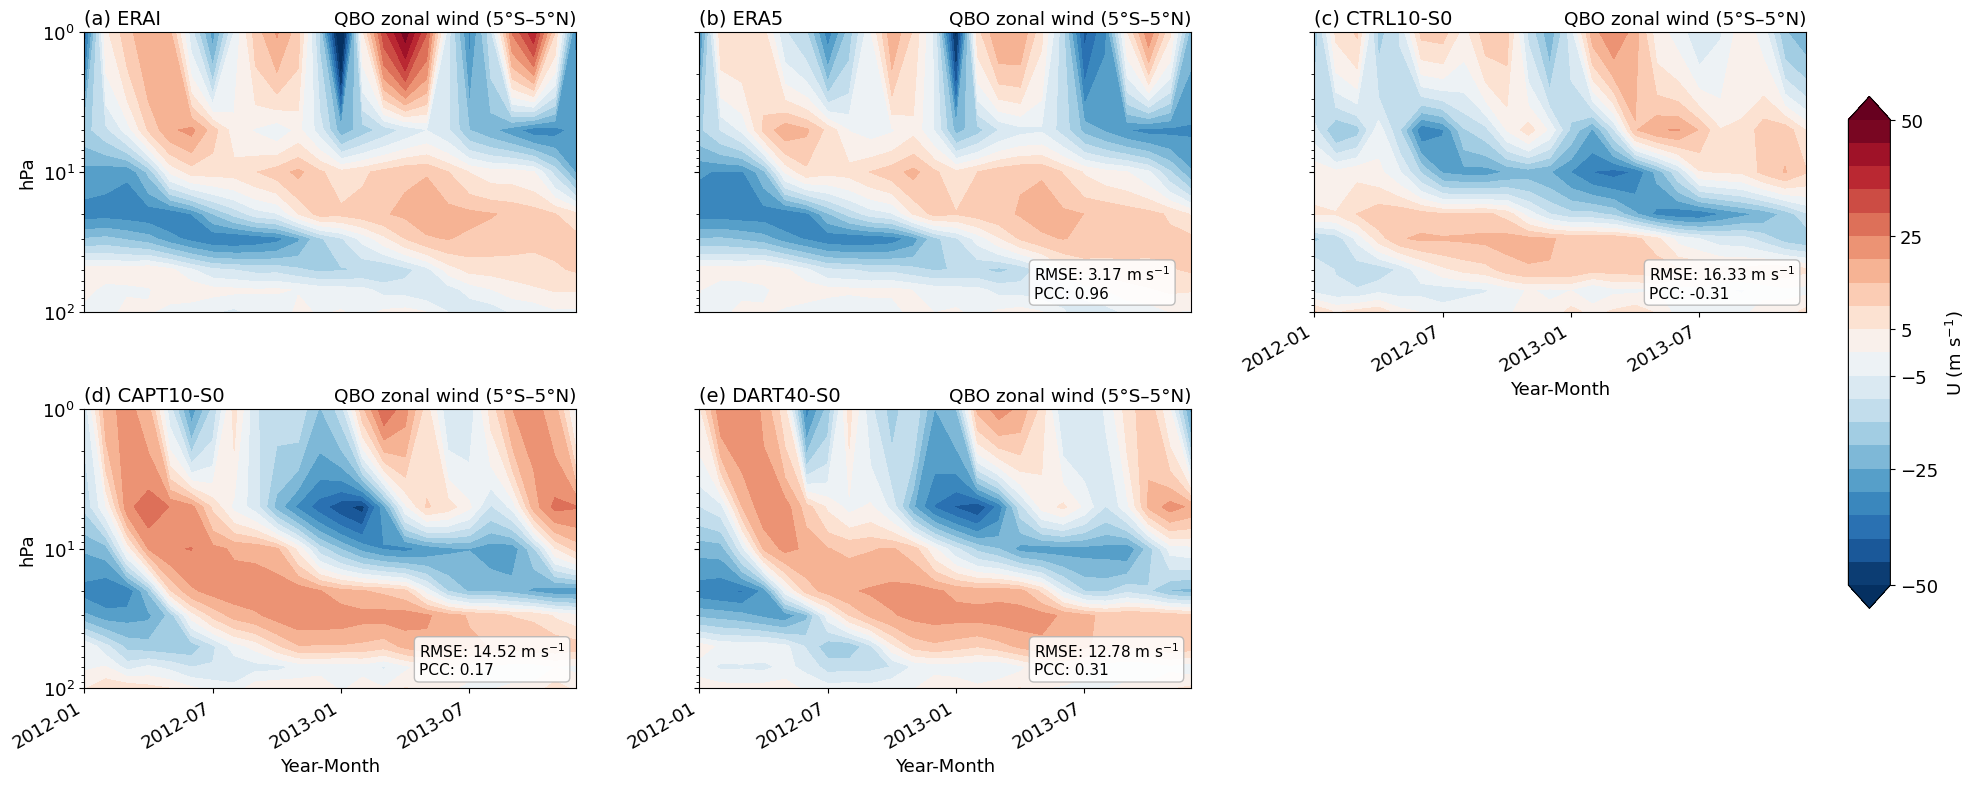

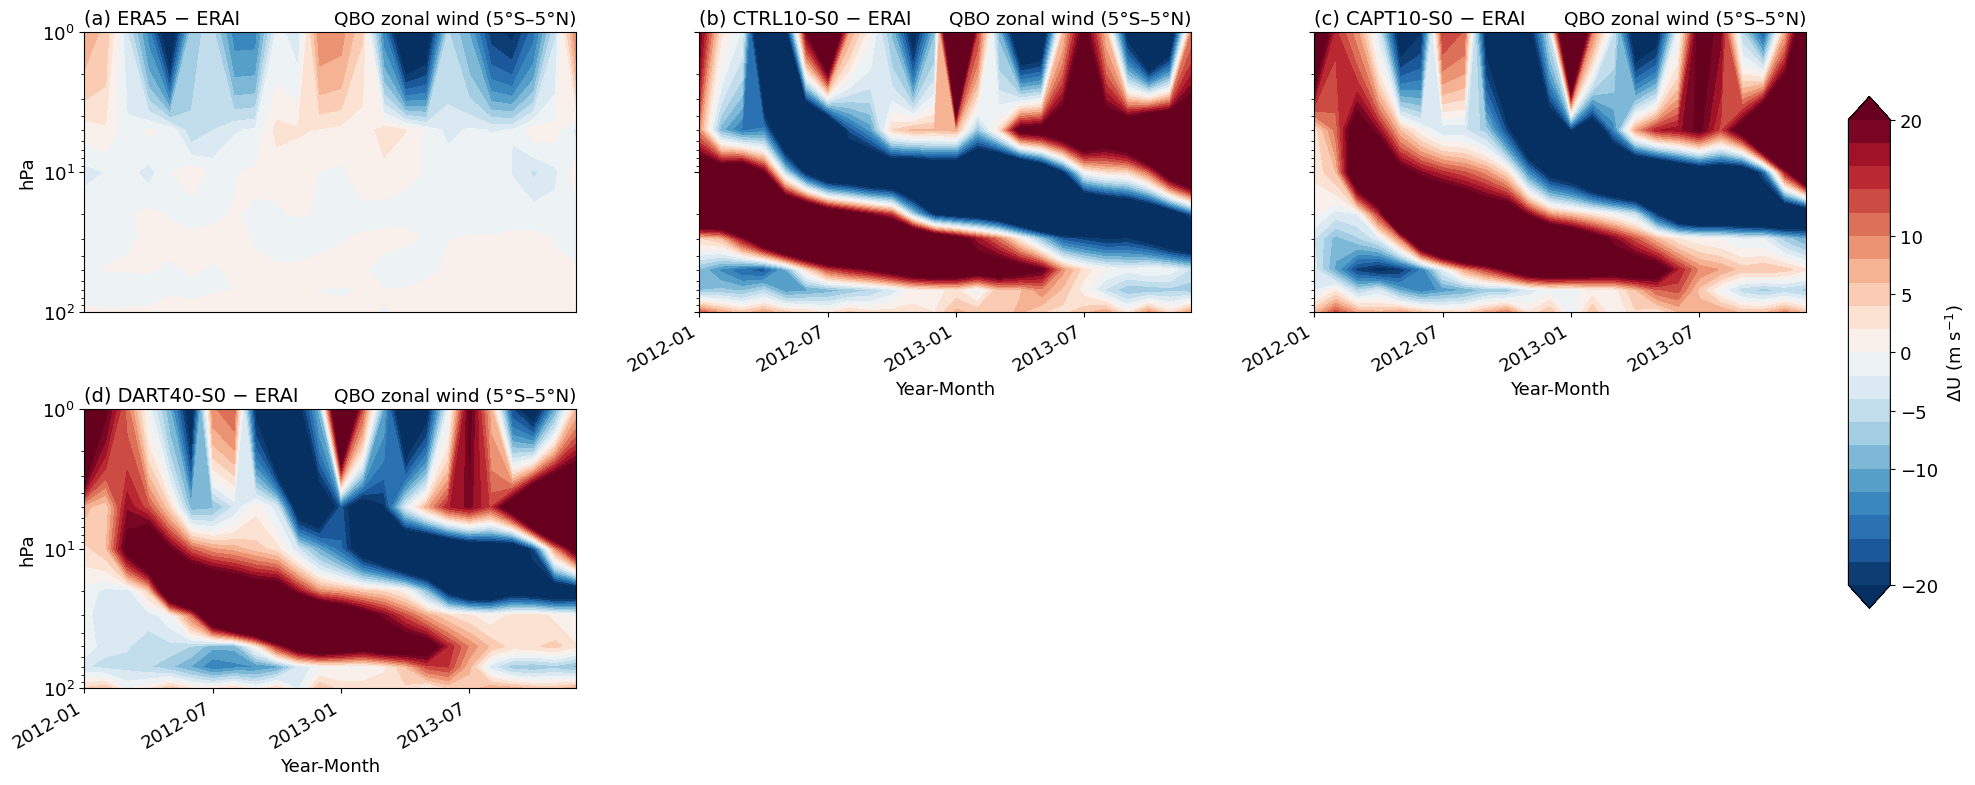

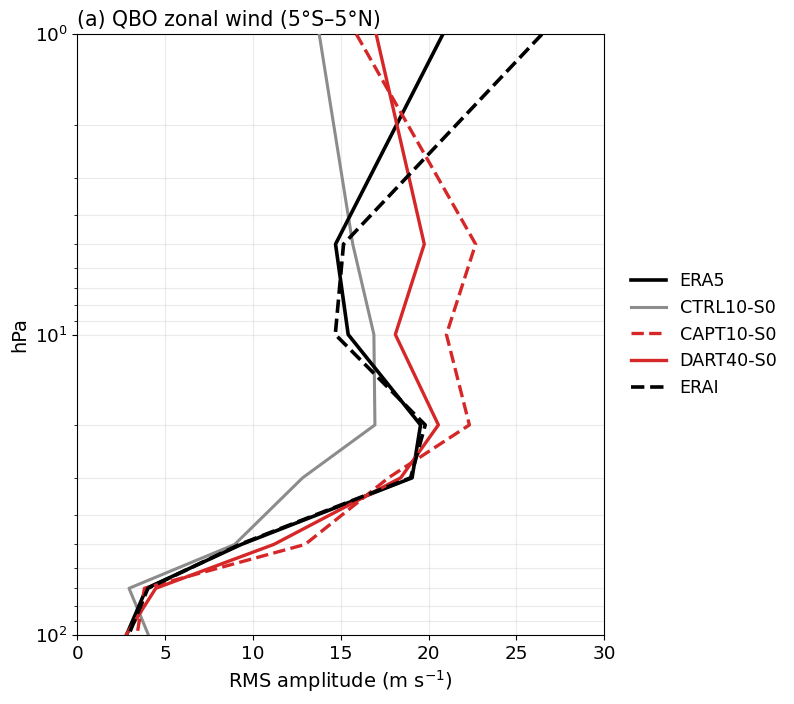

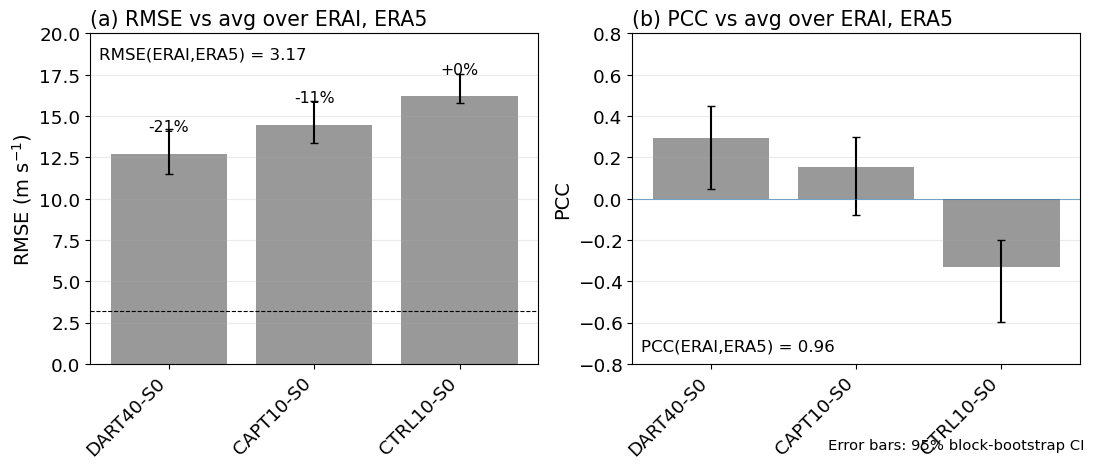

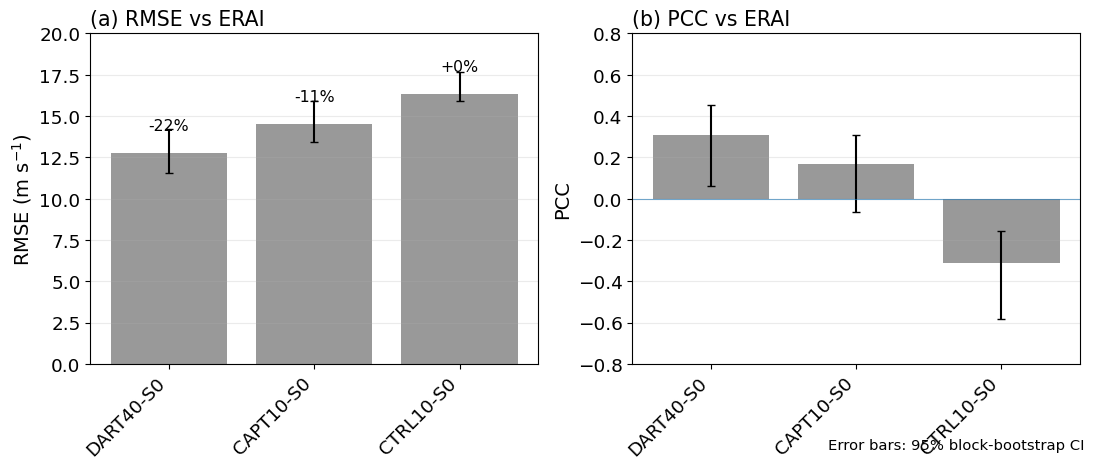

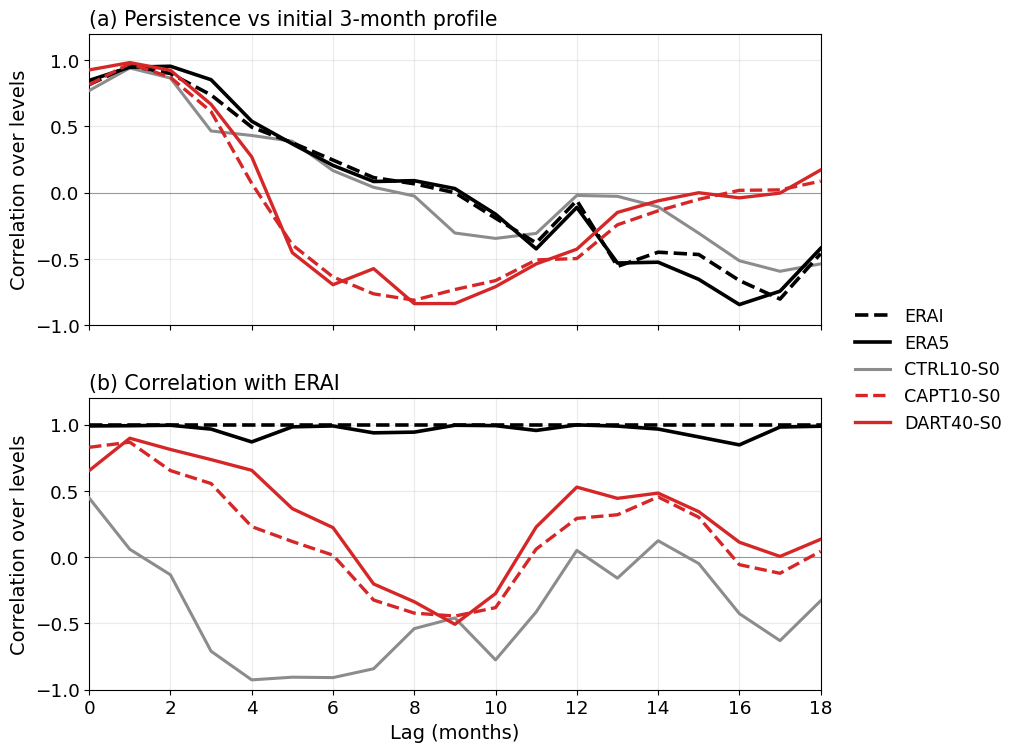

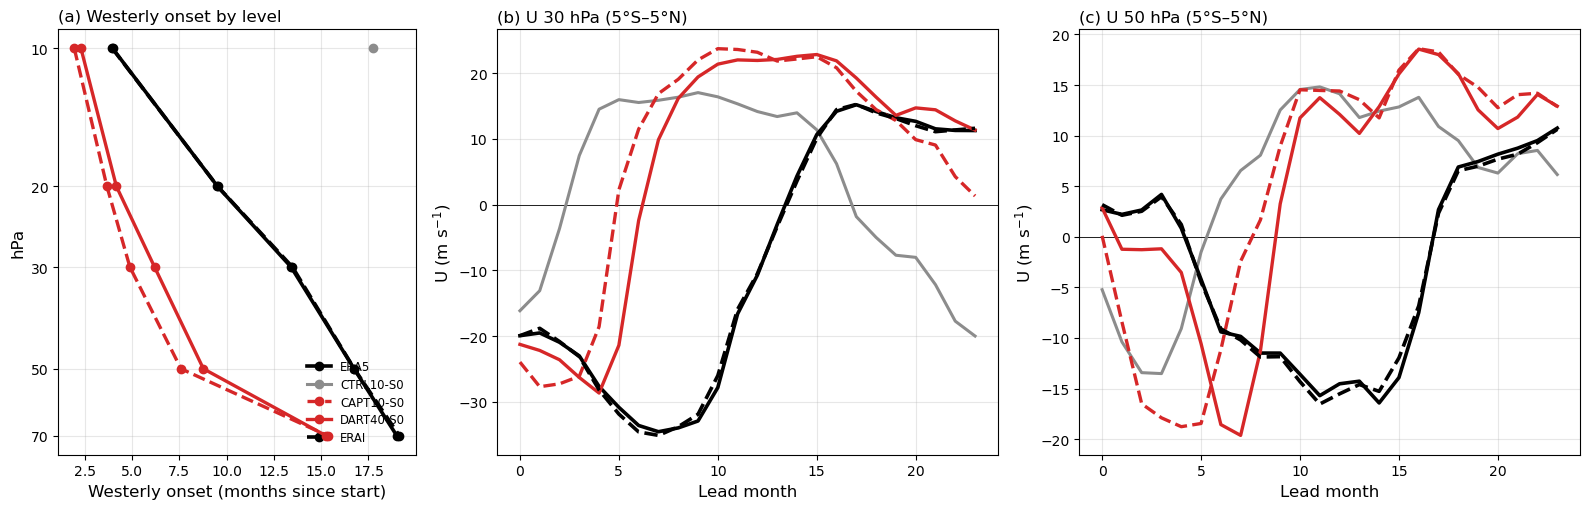

In [9]:
from util.hind_factorial import plot_factorial_scorecard
from util.qbo_plotting import plot_qbo_timing

sources = [OTHER_REANALYSIS, *EXPERIMENTS]
save(plotter.plot_timepressure(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_sections_vs_{REFERENCE}.png")
save(plotter.plot_timepressure_diffs(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_diffs_vs_{REFERENCE}.png")
save(plotter.plot_amplitude(REFERENCE, sources, xlim=(0, 30), font_scale=FONT_SCALE), "qbo_ua_amplitude_rms.png")
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    fig, _ = plotter.plot_skill_bars(refs, EXPERIMENTS, table=skill[tag], font_scale=FONT_SCALE)
    save(fig, f"qbo_ua_skillbars_{tag}.png")
save(plotter.plot_lagcorr_persistence(REFERENCE, sources, font_scale=FONT_SCALE),
     f"qbo_ua_persistence_vs_{REFERENCE}.png")
save(plot_qbo_timing(data_dir, REFERENCE, sources, timing), "qbo_ua_timing.png")
if FACTORIAL:
    save(plot_factorial_scorecard(scores, effects, labels={k: v[0] for k, v in SCORE_COLUMNS.items()},
                                  higher_is_better={k: v[1] for k, v in SCORE_COLUMNS.items()},
                                  title="QBO wind: initial-state attribution"), "qbo_ua_factorial.png")

### 8.2 Temperature and thermal-wind coupling

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ta_ref_clim_sections_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ta_ref_clim_diffs_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ta_amplitude_rms.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_ta_ref_clim_coherence_30hPa.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_t_shear_corr_profiles.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_t_shear_scatter_20-50hPa.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/qbo_thermal_wind_consistency.png
[WRITE] /global/cfs/cdi

,group,r_dT_dS,slope_dT_dS,unbalanced_rms_m1-6,unbalanced_rms_m7-24,mean_dT_m1-6
source,,,,,,
DARTOP,DART atm IC,-0.72,-0.07,2.80,3.05,-1.61
ERA5OP,ERA5 atm IC (CAPT),-0.47,-0.06,8.03,4.31,-6.27
CTRL,piControl atm IC,-0.83,-0.07,3.54,2.86,-2.13


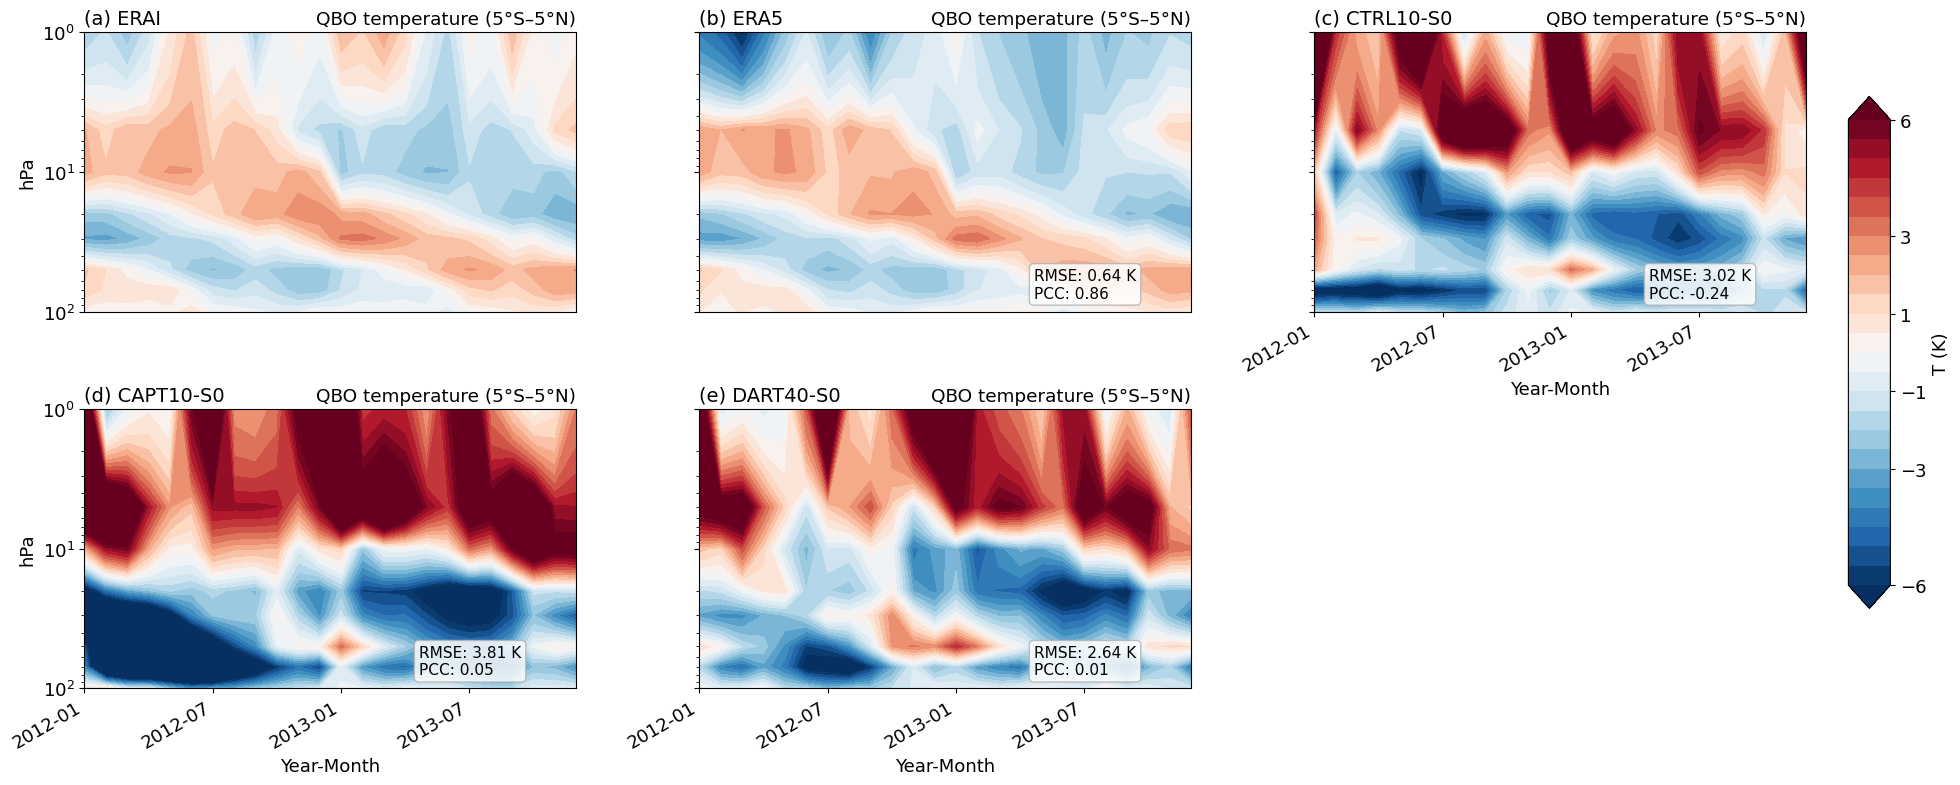

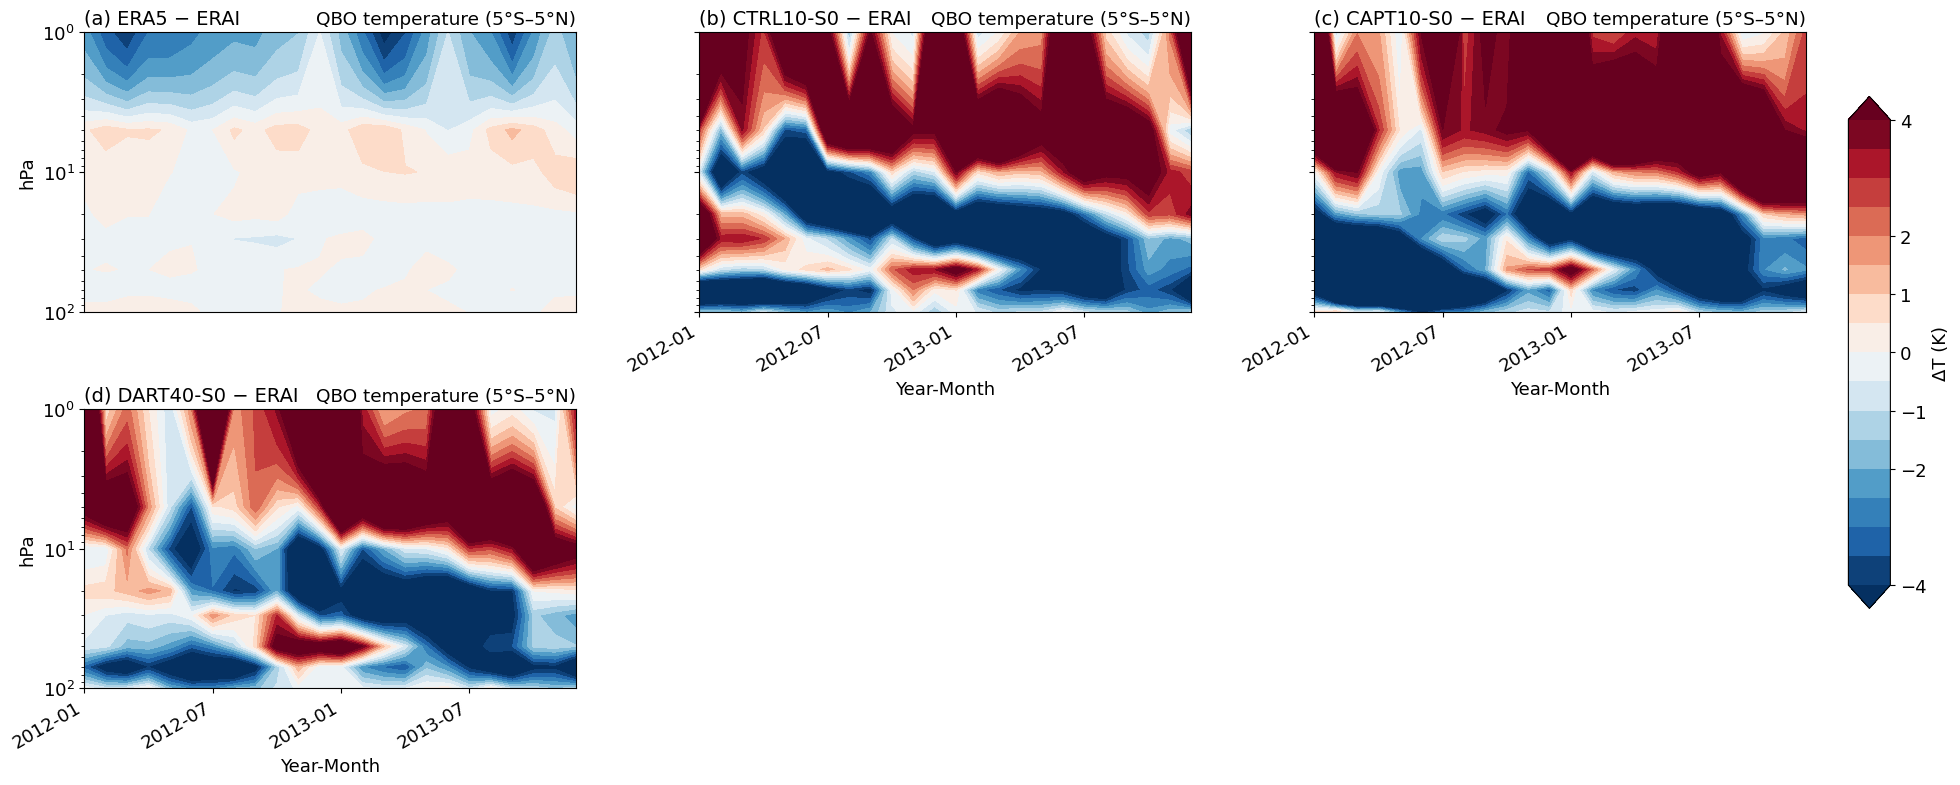

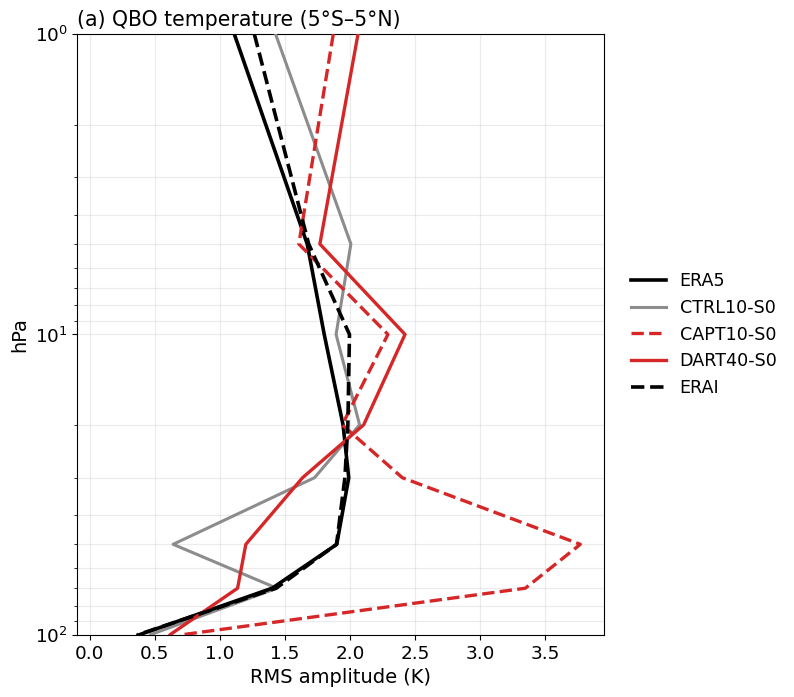

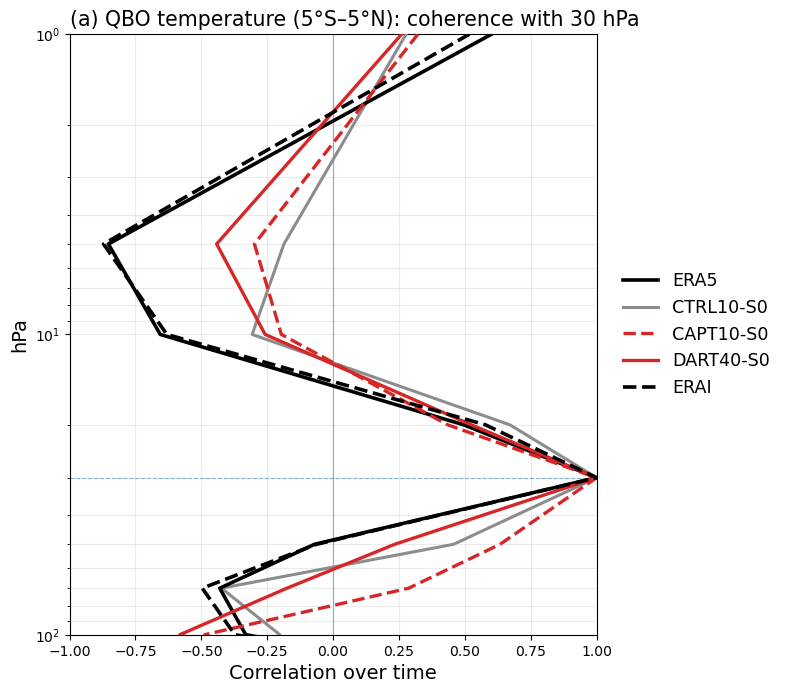

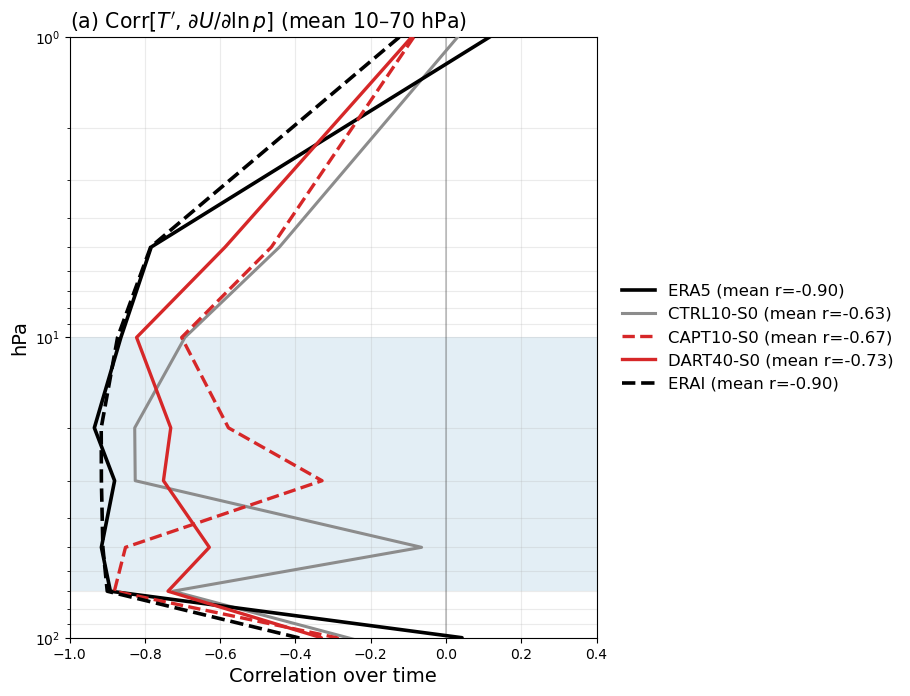

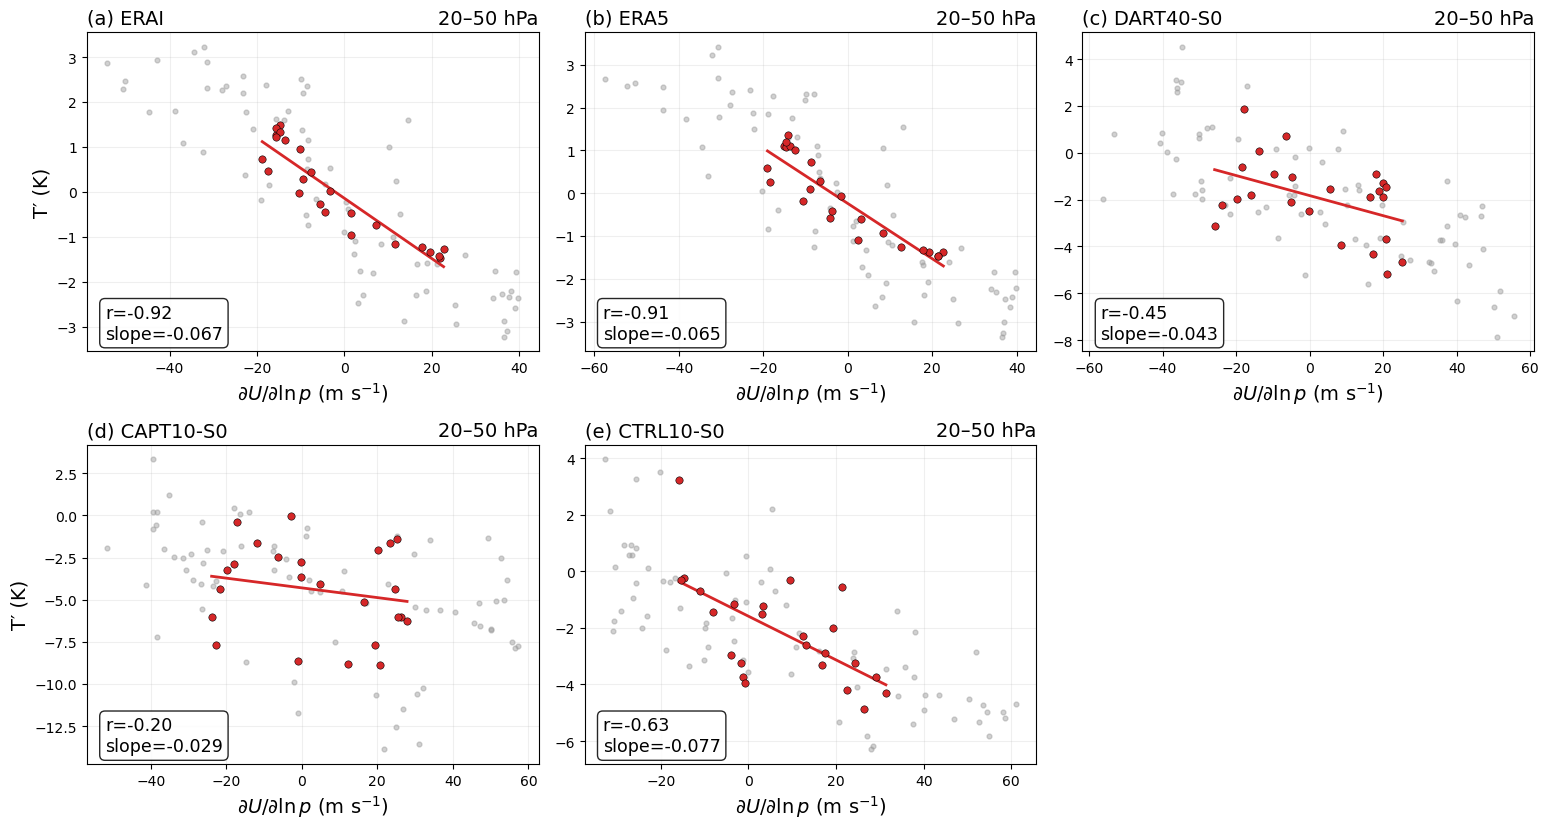

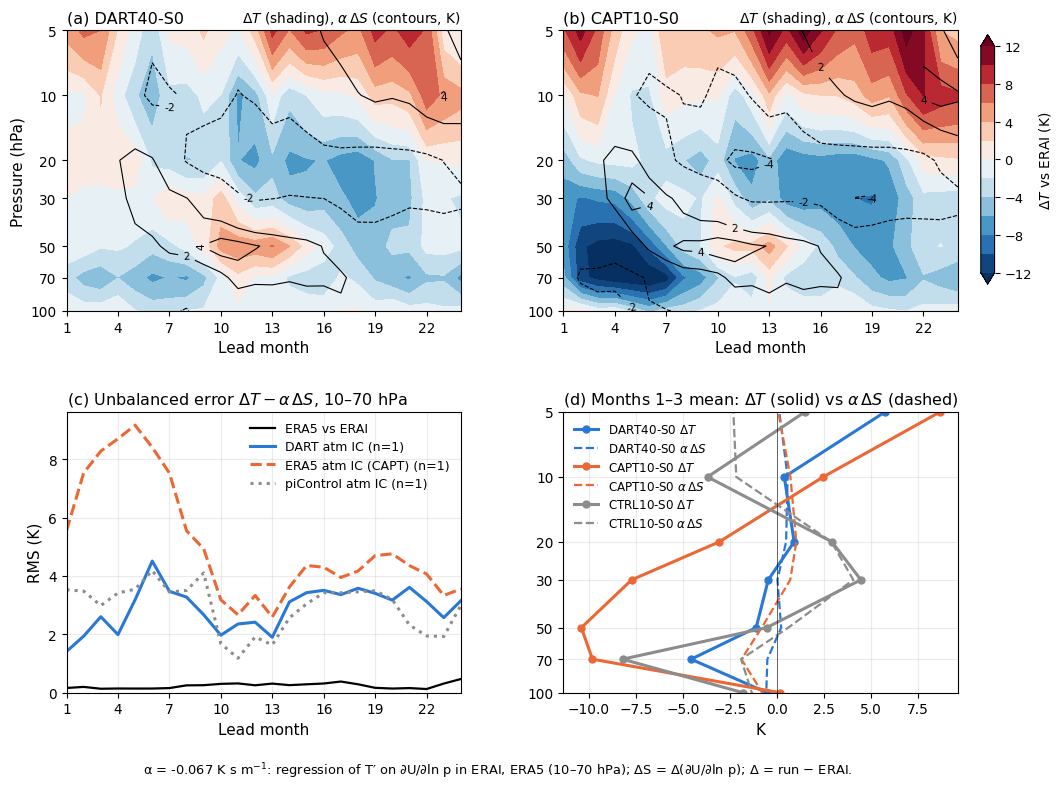

In [10]:
from util.qbo_plotting import (QboPlotParameter, QboPlotter, plot_t_shear_corr_profiles,
                               plot_t_shear_scatter, plot_thermal_wind_consistency)

plotter_t = QboPlotter(QboPlotParameter.for_variable("ta", default_field=FIELD, default_anom_mode=ANOM_MODE),
                       data_dir)
tag = "raw" if FIELD == "qbo" else ANOM_MODE
save(plotter_t.plot_timepressure(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ta_{tag}_sections_vs_{REFERENCE}.png")
save(plotter_t.plot_timepressure_diffs(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ta_{tag}_diffs_vs_{REFERENCE}.png")
save(plotter_t.plot_amplitude(REFERENCE, sources, font_scale=FONT_SCALE), "qbo_ta_amplitude_rms.png")
save(plotter_t.plot_vertical_coherence(REFERENCE, sources, ref_level_hpa=COHERENCE_LEVEL, font_scale=FONT_SCALE),
     f"qbo_ta_{tag}_coherence_{COHERENCE_LEVEL:g}hPa.png")
save(plot_t_shear_corr_profiles(data_dir, REFERENCE, sources, band_hpa=SHEAR_BAND, xlim=(-1.0, 0.4),
                                font_scale=FONT_SCALE), "qbo_t_shear_corr_profiles.png")
save(plot_t_shear_scatter(data_dir, REFERENCE, scatter_sources, layer_hpa=SCATTER_LAYER, font_scale=FONT_SCALE),
     f"qbo_t_shear_scatter_{SCATTER_LAYER[0]:g}-{SCATTER_LAYER[1]:g}hPa.png")
if FACTORIAL:
    save(plot_factorial_scorecard(physics.loc[list(EXPERIMENTS)], physics_effects,
                                  title="QBO temperature and thermal-wind coupling: initial-state attribution"),
         "qbo_ta_physics_factorial.png")

# Paper figure: thermal-wind consistency of the temperature errors, grouped by atmospheric initial state
ATM_GROUPS = {"DART atm IC": ("DARTOP", "DARTBL", "DARTAE"), "ERA5 atm IC (CAPT)": ("ERA5OP", "ERA5DL", "ERA5BL"),
              "piControl atm IC": ("CTRL", "DARTBA")}
groups = {g: [s for s in v if s in EXPERIMENTS] for g, v in ATM_GROUPS.items()}
fig, balance = plot_thermal_wind_consistency(data_dir, REFERENCE, {g: v for g, v in groups.items() if v},
                                             refs=REFERENCES, layer_hpa=SHEAR_BAND, floor=OTHER_REANALYSIS)
save(fig, "qbo_thermal_wind_consistency.png")
balance.to_csv(table_dir / "qbo_thermal_wind_consistency.csv")
print(f"[WRITE] {table_dir / 'qbo_thermal_wind_consistency.csv'}")
display(balance.round(2))